In [ ]:
!pip install transformers dataset torch scikit-learn evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 12.0 MB/s eta 0:00:00
  Attempting uninstall: sqlalchemy
    Found existing installation: SQLAlchemy 2.0.43
    Uninstalling SQLAlchemy-2.0.43:
      Successfully uninstalled SQLAlchemy-2.0.43
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.14.1 requires sqlalchemy<3.0.0,>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.
ipython-sql 0.5.0 requires sqlalchemy>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.


In [ ]:
import numpy as np
import pandas as pd
from datasets import load_dataset, Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)
import evaluate
import os

In [ ]:
#carregar base de dados de teste ,treino e validação
df_train = pd.read_csv('/content/hate_speech_classification_tcc/dados/HateBR/train.csv')
df_val = pd.read_csv('/content/hate_speech_classification_tcc/dados/HateBR/validation.csv')
df_test = pd.read_csv('/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv')

In [ ]:
# Convert pandas DataFrames to Dataset objects
dataset = DatasetDict({
    'train': Dataset.from_pandas(df_train),
    'validation': Dataset.from_pandas(df_val),
    'test': Dataset.from_pandas(df_test)
})
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4500
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 500
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 200
    })
})

# Carregando o modelo BERTurgues e Tokenização

In [ ]:
model_name = "ricardoz/BERTugues-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_batch(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

tokenized_dataset = dataset.map(tokenize_batch, batched=True)

tokenized_dataset = tokenized_dataset.remove_columns(["text"])
tokenized_dataset = tokenized_dataset.rename_column("label", "labels")
tokenized_dataset.set_format("torch")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ricardoz/BERTugues-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# Inspeção de camadas
for name, param in model.named_parameters():
    print(name, param.requires_grad)

for param in model.base_model.embeddings.parameters():
    param.requires_grad = False

bert.embeddings.word_embeddings.weight True
bert.embeddings.position_embeddings.weight True
bert.embeddings.token_type_embeddings.weight True
bert.embeddings.LayerNorm.weight True
bert.embeddings.LayerNorm.bias True
bert.encoder.layer.0.attention.self.query.weight True
bert.encoder.layer.0.attention.self.query.bias True
bert.encoder.layer.0.attention.self.key.weight True
bert.encoder.layer.0.attention.self.key.bias True
bert.encoder.layer.0.attention.self.value.weight True
bert.encoder.layer.0.attention.self.value.bias True
bert.encoder.layer.0.attention.output.dense.weight True
bert.encoder.layer.0.attention.output.dense.bias True
bert.encoder.layer.0.attention.output.LayerNorm.weight True
bert.encoder.layer.0.attention.output.LayerNorm.bias True
bert.encoder.layer.0.intermediate.dense.weight True
bert.encoder.layer.0.intermediate.dense.bias True
bert.encoder.layer.0.output.dense.weight True
bert.encoder.layer.0.output.dense.bias True
bert.encoder.layer.0.output.LayerNorm.weight True


In [ ]:
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "precision_macro": precision.compute(predictions=preds, references=labels, average="macro")["precision"],
        "recall_macro": recall.compute(predictions=preds, references=labels, average="macro")["recall"],
        "f1_macro": f1.compute(predictions=preds, references=labels, average="macro")["f1"],
        "f1_weighted": f1.compute(predictions=preds, references=labels, average="weighted")["f1"],
    }

In [ ]:
# Configuração do treinamento
training_args = TrainingArguments(
    output_dir="./berturgues-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    report_to="none",
)

data_collator = DataCollatorWithPadding(tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,No log,0.203436,0.930000,0.921637,0.910000,0.915521,0.929510
2,0.244100,0.294919,0.910000,0.909014,0.872857,0.888148,0.907924
3,0.244100,0.301584,0.924000,0.912120,0.905714,0.908822,0.923702


TrainOutput(global_step=846, training_loss=0.19012450270055314, metrics={'train_runtime': 305.5258, 'train_samples_per_second': 44.186, 'train_steps_per_second': 2.769, 'total_flos': 887999811840000.0, 'train_loss': 0.19012450270055314, 'epoch': 3.0})

In [ ]:
results = trainer.evaluate(tokenized_dataset["test"])
results_df = pd.DataFrame([results])
print(results_df.to_markdown(index=False))

|   eval_loss |   eval_accuracy |   eval_precision_macro |   eval_recall_macro |   eval_f1_macro |   eval_f1_weighted |   eval_runtime |   eval_samples_per_second |   eval_steps_per_second |   epoch |
|------------:|----------------:|-----------------------:|--------------------:|----------------:|-------------------:|---------------:|--------------------------:|------------------------:|--------:|
|    0.978401 |           0.715 |               0.665242 |            0.672619 |        0.668364 |           0.718109 |         1.3896 |                   143.927 |                   9.355 |       3 |


In [ ]:
results_df = results_df[['eval_accuracy','eval_f1_macro','eval_recall_macro','eval_precision_macro']]
results_df.head()

,eval_accuracy,eval_f1_macro,eval_recall_macro,eval_precision_macro
0,0.715,0.668364,0.672619,0.665242


In [ ]:
#Arredondar os resultados de results_df
results_df = results_df.round(3)*100
results_df.head()

,eval_accuracy,eval_f1_macro,eval_recall_macro,eval_precision_macro
0,71.5,66.8,67.3,66.5


📊 Resultados Globais no Teste(BERTurgues):

|   eval_loss |   eval_accuracy |   eval_precision_macro |   eval_recall_macro |   eval_f1_macro |   eval_f1_weighted |   eval_runtime |   eval_samples_per_second |   eval_steps_per_second |   epoch |
|------------:|----------------:|-----------------------:|--------------------:|----------------:|-------------------:|---------------:|--------------------------:|------------------------:|--------:|
|    0.978401 |           0.715 |               0.665242 |            0.672619 |        0.668364 |           0.718109 |         1.3445 |                    148.76 |                   9.669 |       3 |


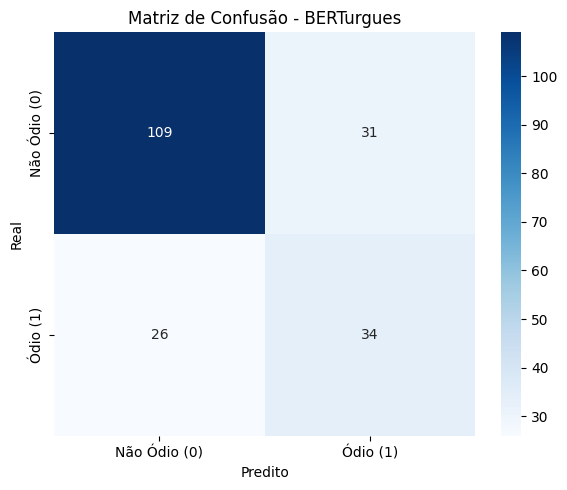


📋 Classification Report(BERTurgues):

              precision    recall  f1-score   support

Não Ódio (0)     0.8074    0.7786    0.7927       140
    Ódio (1)     0.5231    0.5667    0.5440        60

    accuracy                         0.7150       200
   macro avg     0.6652    0.6726    0.6684       200
weighted avg     0.7221    0.7150    0.7181       200


✅ Resultados salvos em 'bert/'


<Figure size 640x480 with 0 Axes>

In [ ]:
from helpers.utils import save_metrics_and_plots

# 1) Avaliação com métricas globais
results = trainer.evaluate(tokenized_dataset["test"])
predictions = trainer.predict(tokenized_dataset["test"])
y_true = predictions.label_ids
y_pred = np.argmax(predictions.predictions, axis=-1)

# 2) Salvar métricas, matriz de confusão e relatório
save_metrics_and_plots(
    results=results,
    y_true=y_true,
    y_pred=y_pred,
    output_dir="/content/hate_speech_classification_tcc/dados/resultados/bert/bertimbau-large",
    model_name="BERTimbau-Large"
)

In [ ]:
results_df.to_csv('results_berturgues.csv', index=False)